# Advanced Retail Analytics and RFM Customer Segmentation
**Author:** Shreyas Kamat  |  **Source:** UCI Online Retail dataset

Updated, self-contained version of the original retail analysis. It includes
exploratory sales analysis, K-Means clustering, corrected RFM segmentation,
statistical diagnostics, Random Forest quantity modelling and product-level
weekly SARIMA forecasting. All claims should be interpreted as exploratory.

Positive sales exclude cancellations and refunds; they are **not net revenue**.
K-Means clusters cannot establish verified B2B/B2C customer categories.

**Run:** Place `data.csv` beside the notebook or script; run from top to bottom.
Charts are saved under `figures/`, tables under `outputs/`.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GroupShuffleSplit
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error
import statsmodels.api as sm

RANDOM_STATE = 42
DATA_PATH = Path("data.csv")
OUTPUT_DIR = Path("outputs")
FIG_DIR = Path("figures")
OUTPUT_DIR.mkdir(exist_ok=True, parents=True)
FIG_DIR.mkdir(exist_ok=True, parents=True)
if not DATA_PATH.is_file():
    raise FileNotFoundError("Put data.csv in the current folder, or change DATA_PATH.")
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 160, "font.size": 10})

## 1. Load, validate, clean
The source contains 541,909 rows including missing customer IDs, cancellations
and zero/negative prices. Following the original project, analysis uses only
**positive quantities and unit prices** with non-missing customer IDs.
Dates mix month-first dash and slash separators; parse with `format="mixed"`.
The alternate `online_shoppers.csv` holds the same transactions in a different
timestamp format. `customer_data.csv` belongs to a different course exercise.

In [2]:
raw = pd.read_csv(DATA_PATH, encoding="ISO-8859-1", dtype={"InvoiceNo": str, "StockCode": str})
required = {"InvoiceNo", "InvoiceDate", "CustomerID", "Quantity", "UnitPrice", "Description", "Country"}
missing = required.difference(raw.columns)
if missing:
    raise ValueError(f"Missing dataset columns: {sorted(missing)}")
# Source timestamps mix dash and slash separators, with month-first dates.
raw["InvoiceDate_dt"] = pd.to_datetime(
    raw["InvoiceDate"], format="mixed", dayfirst=False, errors="coerce"
)
clean = raw.loc[
    raw["CustomerID"].notna() & raw["InvoiceDate_dt"].notna()
    & raw["InvoiceNo"].notna() & (raw["Quantity"] > 0)
    & (raw["UnitPrice"] > 0)
].copy()
clean["CustomerID"] = clean["CustomerID"].astype("int64")
clean["TotalSales"] = clean["Quantity"] * clean["UnitPrice"]
clean["InvoiceHour"] = clean["InvoiceDate_dt"].dt.hour
clean["Quarter"] = clean["InvoiceDate_dt"].dt.to_period("Q").astype(str)
clean["YearMonth"] = clean["InvoiceDate_dt"].dt.to_period("M").astype(str)
quality = {
    "raw_rows": int(len(raw)), "clean_rows": int(len(clean)),
    "excluded_rows": int(len(raw)-len(clean)),
    "missing_customer_rows": int(raw["CustomerID"].isna().sum()),
    "nonpositive_quantity_rows": int((raw["Quantity"] <= 0).sum()),
    "nonpositive_price_rows": int((raw["UnitPrice"] <= 0).sum()),
    "unique_customers": int(clean["CustomerID"].nunique()),
    "unique_invoices": int(clean["InvoiceNo"].nunique()),
    "positive_sales_gbp": float(clean["TotalSales"].sum()),
    "first_date": str(clean["InvoiceDate_dt"].min()),
    "last_date": str(clean["InvoiceDate_dt"].max())
}
print("=== DATA QUALITY ===")
print(pd.Series(quality).to_string())
assert quality["raw_rows"] == 541909
assert quality["clean_rows"] == 397884
assert quality["unique_customers"] == 4338

=== DATA QUALITY ===
raw_rows                                  541909
clean_rows                                397884
excluded_rows                             144025
missing_customer_rows                     135080
nonpositive_quantity_rows                  10624
nonpositive_price_rows                      2517
unique_customers                            4338
unique_invoices                            18532
positive_sales_gbp                   8911407.904
first_date                   2010-12-01 08:26:00
last_date                    2011-12-09 12:50:00


## 2. Retail sales exploration
The original project focused on **WHITE HANGING HEART T-LIGHT HOLDER**.
Its quarterly revenue is product-specific. The monthly chart separately shows
the positive sales of **all** products.


=== 2011 SIGNATURE PRODUCT QUARTERLY SALES (£) ===
Quarter
2011Q1    25154.90
2011Q2    24683.97
2011Q3    20591.07
2011Q4    20416.16
All-products positive sales: £8,911,407.90


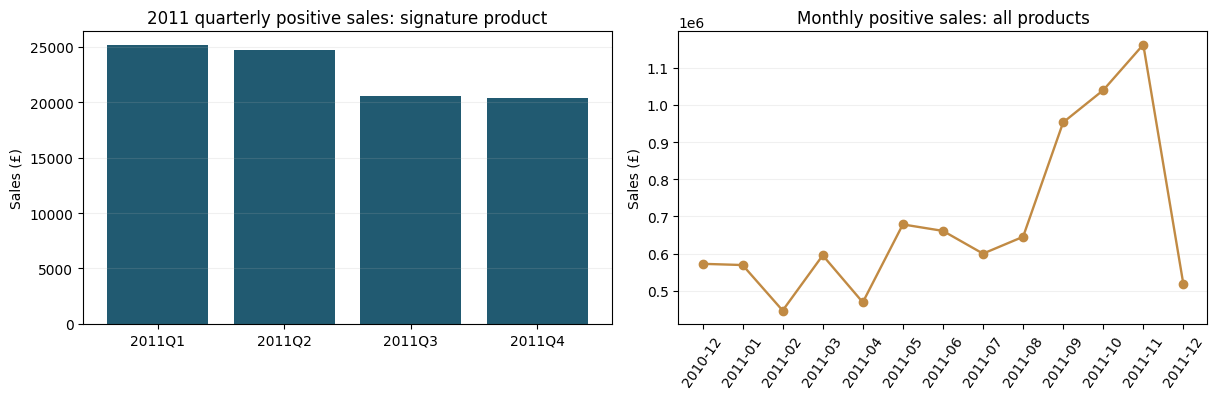

In [3]:
target_product = "WHITE HANGING HEART T-LIGHT HOLDER"
product_2011 = clean.loc[
    clean["Description"].eq(target_product)
    & clean["InvoiceDate_dt"].dt.year.eq(2011)
].copy()
quarterly_product = product_2011.groupby("Quarter")["TotalSales"].sum().sort_index()
monthly_all = clean.groupby("YearMonth")["TotalSales"].sum().sort_index()
print("\n=== 2011 SIGNATURE PRODUCT QUARTERLY SALES (£) ===")
print(quarterly_product.round(2).to_string())
print(f"All-products positive sales: £{quality['positive_sales_gbp']:,.2f}")
fig, axes = plt.subplots(1, 2, figsize=(12.3, 4.1))
axes[0].bar(quarterly_product.index, quarterly_product.values, color="#215a71")
axes[0].set(title="2011 quarterly positive sales: signature product", ylabel="Sales (£)")
axes[1].plot(monthly_all.index, monthly_all.values, marker="o", color="#c18a43", linewidth=1.7)
axes[1].set(title="Monthly positive sales: all products", ylabel="Sales (£)")
axes[1].tick_params(axis="x", rotation=55)
for ax in axes: ax.grid(axis="y", alpha=0.18)
fig.tight_layout()
fig.savefig(FIG_DIR / "sales_trends.png", bbox_inches="tight")
plt.show()

## 3. K-Means customer clustering
Retain three descriptive behaviour clusters from the original project. Never
infer a customer's business status from an unsupervised cluster label.
Inputs: customer total spend, units, mean line-item quantity, distinct invoices.


=== K-MEANS CLUSTER PROFILES ===
         Customers  AvgSpend  AvgUnits  AvgOrders
Cluster                                          
0             1700    270.01    142.39       1.34
1             1811   1104.60    657.36       3.19
2              827   7801.64   4516.66      12.68


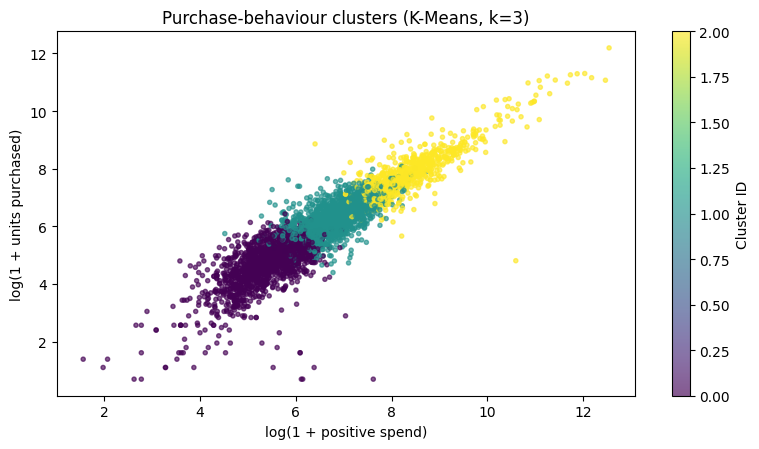

In [4]:
customers = clean.groupby("CustomerID").agg(
    TotalSpend=("TotalSales", "sum"),
    TotalUnits=("Quantity", "sum"),
    AvgQuantity=("Quantity", "mean"),
    OrderCount=("InvoiceNo", "nunique")
)
cluster_features = ["TotalSpend", "TotalUnits", "AvgQuantity", "OrderCount"]
scaled = StandardScaler().fit_transform(np.log1p(customers[cluster_features]))
kmeans = KMeans(n_clusters=3, random_state=RANDOM_STATE, n_init=10)
customers["Cluster"] = kmeans.fit_predict(scaled)
high_spend_cluster = customers.groupby("Cluster")["TotalSpend"].mean().idxmax()
customers["ClusterGroup"] = np.where(customers["Cluster"].eq(high_spend_cluster),
                                      "High-spend cluster", "Other clusters")
cluster_summary = customers.groupby("Cluster").agg(
    Customers=("TotalSpend", "size"), AvgSpend=("TotalSpend", "mean"),
    AvgUnits=("TotalUnits", "mean"), AvgOrders=("OrderCount", "mean")
)
print("\n=== K-MEANS CLUSTER PROFILES ===")
print(cluster_summary.round(2).to_string())
customers.reset_index().to_csv(OUTPUT_DIR / "customer_clusters.csv", index=False)
fig, ax = plt.subplots(figsize=(8, 4.6))
sc = ax.scatter(np.log1p(customers["TotalSpend"]), np.log1p(customers["TotalUnits"]),
                c=customers["Cluster"], cmap="viridis", s=9, alpha=0.65)
ax.set(xlabel="log(1 + positive spend)", ylabel="log(1 + units purchased)",
       title="Purchase-behaviour clusters (K-Means, k=3)")
fig.colorbar(sc, ax=ax, label="Cluster ID")
fig.tight_layout()
fig.savefig(FIG_DIR / "kmeans_clusters.png", bbox_inches="tight")
plt.show()

## 4. RFM: Recency, Frequency, Monetary (new)
- Recency = days since last positive purchase; **lower days = better**.
- Frequency = unique invoices; counting rows overstates repeat purchases.
- Monetary = sum of positive line-item values, not mean value per row.
Each metric receives a percentile rank score of 1 to 4. We use equal rank
treatment for ties instead of `qcut`, which fails on repeated frequencies.
Four segment thresholds follow the course exercise; they are *illustrative*.


=== RFM SEGMENTATION ===
                 Customers  AvgRecencyDays  AvgDistinctInvoices  PositiveSales  CustomerSharePct  SalesSharePct
RFM_Segment                                                                                                    
Superstar              876           13.34                12.06     5903469.08             20.19          66.25
Future Champion       1159           46.94                 3.96     1944248.34             26.72          21.82
High Potential         886           83.65                 1.95      664483.38             20.42           7.46
Low Relevance         1417          184.35                 1.16      399207.10             32.66           4.48


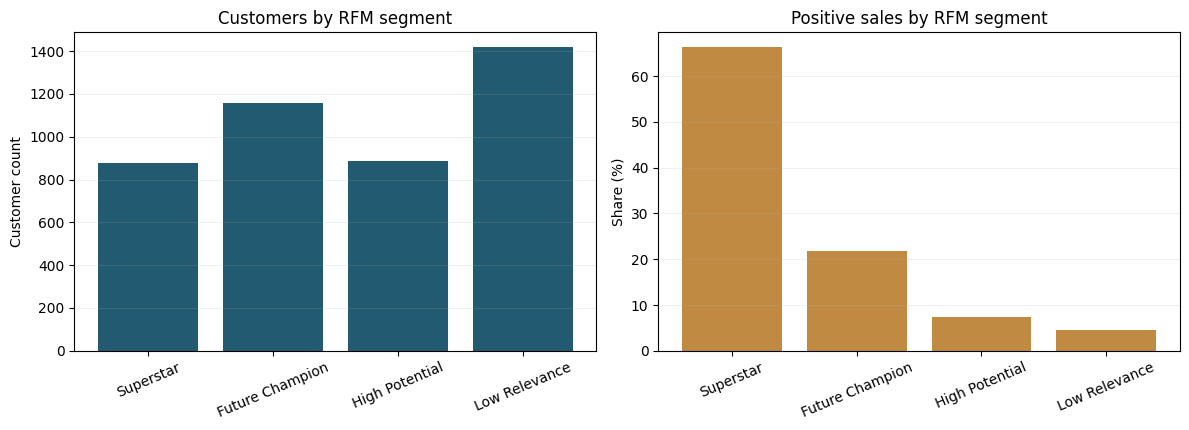


K-Means vs RFM customer counts:
 RFM_Segment  Future Champion  High Potential  Low Relevance  Superstar
Cluster                                                               
0                         81             365           1254          0
1                        940             514            163        194
2                        138               7              0        682


In [5]:
snapshot_date = clean["InvoiceDate_dt"].max() + pd.Timedelta(days=1)
rfm = clean.groupby("CustomerID").agg(
    LastPurchase=("InvoiceDate_dt", "max"),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("TotalSales", "sum")
)
rfm["Recency"] = (snapshot_date - rfm["LastPurchase"]).dt.days.astype(int)
rfm["R"] = 5 - np.ceil(rfm["Recency"].rank(method="average", pct=True) * 4).astype(int)
rfm["F"] = np.ceil(rfm["Frequency"].rank(method="average", pct=True) * 4).astype(int)
rfm["M"] = np.ceil(rfm["Monetary"].rank(method="average", pct=True) * 4).astype(int)
rfm["RFM_Score"] = rfm[["R", "F", "M"]].sum(axis=1)
rfm["RFM_Segment"] = np.select(
    [rfm["RFM_Score"] >= 11, rfm["RFM_Score"] >= 8, rfm["RFM_Score"] >= 6],
    ["Superstar", "Future Champion", "High Potential"], default="Low Relevance"
)
segment_order = ["Superstar", "Future Champion", "High Potential", "Low Relevance"]
rfm_summary = rfm.groupby("RFM_Segment").agg(
    Customers=("Monetary", "size"), AvgRecencyDays=("Recency", "mean"),
    AvgDistinctInvoices=("Frequency", "mean"), PositiveSales=("Monetary", "sum")
).reindex(segment_order)
rfm_summary["CustomerSharePct"] = rfm_summary["Customers"] / len(rfm) * 100
rfm_summary["SalesSharePct"] = rfm_summary["PositiveSales"] / rfm["Monetary"].sum() * 100
assert rfm_summary["Customers"].sum() == quality["unique_customers"]
assert np.isclose(rfm["Monetary"].sum(), clean["TotalSales"].sum())
print("\n=== RFM SEGMENTATION ===")
print(rfm_summary.round(2).to_string())
rfm.reset_index().to_csv(OUTPUT_DIR / "rfm_customer_segments.csv", index=False)
rfm_summary.reset_index().to_csv(OUTPUT_DIR / "rfm_segment_summary.csv", index=False)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
axes[0].bar(rfm_summary.index, rfm_summary["Customers"], color="#215a71")
axes[0].set(title="Customers by RFM segment", ylabel="Customer count")
axes[1].bar(rfm_summary.index, rfm_summary["SalesSharePct"], color="#c18a43")
axes[1].set(title="Positive sales by RFM segment", ylabel="Share (%)")
for ax in axes:
    ax.tick_params(axis="x", rotation=23)
    ax.grid(axis="y", alpha=0.18)
fig.tight_layout()
fig.savefig(FIG_DIR / "rfm_segment_overview.png", bbox_inches="tight")
plt.show()

cross_tab = customers[["Cluster"]].join(rfm[["RFM_Segment"]]).groupby(
    ["Cluster", "RFM_Segment"]
).size().unstack(fill_value=0)
print("\nK-Means vs RFM customer counts:\n", cross_tab.to_string())
cross_tab.to_csv(OUTPUT_DIR / "rfm_vs_kmeans.csv")

## 5. Statistical diagnostics for the signature product
Revisit the original product's September/October **observed daily sales**.
Shapiro-Wilk tests normality of the *sample*, not whether a method is
"parametric". A raw target distribution need not be normal for OLS to work;
when relevant, examine conditional residuals and model diagnostics.

In [6]:
daily_product = product_2011.groupby(product_2011["InvoiceDate_dt"].dt.normalize())[
    "TotalSales"
].sum().sort_index()
sep = daily_product[daily_product.index.month == 9]
octb = daily_product[daily_product.index.month == 10]
shapiro_sep = stats.shapiro(sep)
shapiro_oct = stats.shapiro(octb)
mann_whitney = stats.mannwhitneyu(sep, octb, alternative="two-sided")
stat_results = {
    "september_observed_days": int(len(sep)),
    "october_observed_days": int(len(octb)),
    "september_shapiro_stat": float(shapiro_sep.statistic),
    "september_shapiro_p": float(shapiro_sep.pvalue),
    "october_shapiro_stat": float(shapiro_oct.statistic),
    "october_shapiro_p": float(shapiro_oct.pvalue),
    "mann_whitney_u": float(mann_whitney.statistic),
    "mann_whitney_p": float(mann_whitney.pvalue)
}
print("\n=== SEPTEMBER / OCTOBER DIAGNOSTICS ===")
print(pd.Series(stat_results).round(6).to_string())
print("Only days with product purchases appear in this daily comparison.")


=== SEPTEMBER / OCTOBER DIAGNOSTICS ===
september_observed_days     26.000000
october_observed_days       26.000000
september_shapiro_stat       0.708671
september_shapiro_p          0.000007
october_shapiro_stat         0.813667
october_shapiro_p            0.000303
mann_whitney_u             427.000000
mann_whitney_p               0.105277
Only days with product purchases appear in this daily comparison.


## 6. Random Forest quantity prediction
Preserve the original two-group comparison, but call the groups **high-spend
cluster** and **other clusters**, not verified wholesale/retail businesses.
Models predict `log(1 + Quantity)` from unit price and invoice hour.
Randomly split *invoice groups* (not rows) to avoid shared invoice leakage.
These are exploratory holdouts, not chronological production validation.
Importance of UnitPrice **is not causal price elasticity**.

In [7]:
model_data = clean.merge(customers[["ClusterGroup"]], left_on="CustomerID",
                         right_index=True, how="left", validate="many_to_one")
rf_results = []
for group_name in ["Other clusters", "High-spend cluster"]:
    part = model_data.loc[model_data["ClusterGroup"].eq(group_name)].copy()
    x = part[["UnitPrice", "InvoiceHour"]]
    y = np.log1p(part["Quantity"])
    splitter = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=RANDOM_STATE)
    train_i, test_i = next(splitter.split(x, y, groups=part["InvoiceNo"]))
    model = RandomForestRegressor(
        n_estimators=60, min_samples_leaf=3, max_depth=18,
        random_state=RANDOM_STATE, n_jobs=-1
    )
    model.fit(x.iloc[train_i], y.iloc[train_i])
    pred = model.predict(x.iloc[test_i])
    rf_results.append({
        "ClusterGroup": group_name,
        "TestRows": int(len(test_i)),
        "R2_LogQuantity": float(r2_score(y.iloc[test_i], pred)),
        "MAE_LogUnits": float(mean_absolute_error(y.iloc[test_i], pred)),
        "UnitPriceImportance": float(model.feature_importances_[0]),
        "InvoiceHourImportance": float(model.feature_importances_[1])
    })
rf_metrics = pd.DataFrame(rf_results)
print("\n=== RANDOM FOREST INVOICE-LEVEL HOLDOUT ===")
print(rf_metrics.round(4).to_string(index=False))
rf_metrics.to_csv(OUTPUT_DIR / "random_forest_metrics.csv", index=False)


=== RANDOM FOREST INVOICE-LEVEL HOLDOUT ===
      ClusterGroup  TestRows  R2_LogQuantity  MAE_LogUnits  UnitPriceImportance  InvoiceHourImportance
    Other clusters     34231          0.2940        0.5989               0.7978                 0.2022
High-spend cluster     43172          0.3381        0.6651               0.8746                 0.1254


## 7. Weekly signature-product forecasting
The old notebook incorrectly called a single product's revenue "enterprise
revenue" and interpreted a 14-week AR coefficient as variance explained.
We explicitly restrict the forecast to the signature product and test a
14-week SARIMA on the *last eight held-out weeks*. Baselines: the last
training week (flat naive) and lag-14 (seasonal naive, if applicable).
49 weeks is a short sample for 14-week seasonality. Do not treat as validated
inventory advice, and do not treat negative model intervals as possible sales.


=== PRODUCT-ONLY 8-WEEK FORECAST HOLDOUT ===
weeks_observed                49.00
test_weeks                     8.00
sarima_test_mae_gbp         1506.58
flat_naive_test_mae_gbp     1020.69
lag14_naive_test_mae_gbp    1385.94
train_lag14_ar_coef            0.66


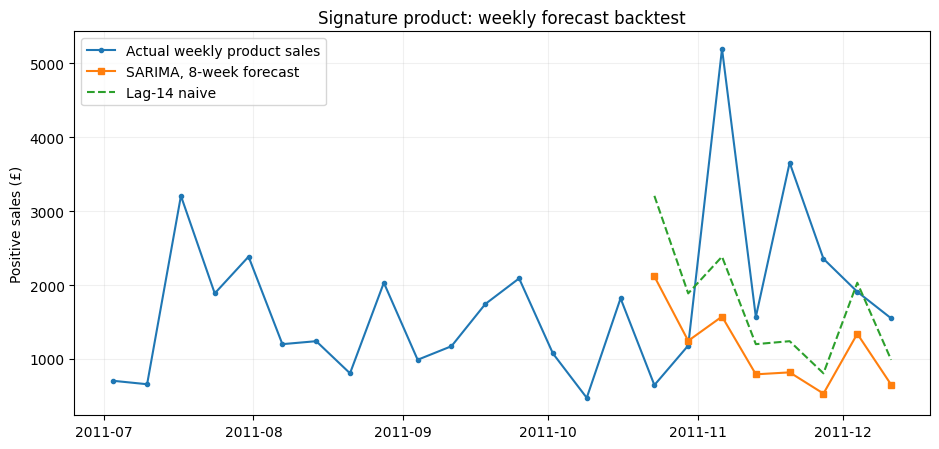

In [8]:
weekly_product = (product_2011.set_index("InvoiceDate_dt")["TotalSales"]
                  .resample("W-SUN").sum())
train = weekly_product.iloc[:-8]
test = weekly_product.iloc[-8:]
seasonal_lag = 14
sarima_train = sm.tsa.statespace.SARIMAX(
    train, order=(0, 0, 0), seasonal_order=(1, 0, 0, seasonal_lag),
    enforce_stationarity=False, enforce_invertibility=False
).fit(disp=False)
test_pred = sarima_train.get_forecast(steps=len(test)).predicted_mean
flat_naive = pd.Series(train.iloc[-1], index=test.index)
seasonal_naive = weekly_product.shift(seasonal_lag).loc[test.index]
forecast_metrics = {
    "weeks_observed": int(len(weekly_product)),
    "test_weeks": int(len(test)),
    "sarima_test_mae_gbp": float(mean_absolute_error(test, test_pred)),
    "flat_naive_test_mae_gbp": float(mean_absolute_error(test, flat_naive)),
    "lag14_naive_test_mae_gbp": float(mean_absolute_error(test, seasonal_naive)),
    "train_lag14_ar_coef": float(sarima_train.params.get("ar.S.L14", np.nan))
}
print("\n=== PRODUCT-ONLY 8-WEEK FORECAST HOLDOUT ===")
print(pd.Series(forecast_metrics).round(2).to_string())
fig, ax = plt.subplots(figsize=(9.5, 4.6))
ax.plot(weekly_product.iloc[-24:].index, weekly_product.iloc[-24:].values,
        label="Actual weekly product sales", marker="o", markersize=3)
ax.plot(test.index, test_pred, label="SARIMA, 8-week forecast", marker="s", markersize=4)
ax.plot(test.index, seasonal_naive, label="Lag-14 naive", linestyle="--")
ax.set(title="Signature product: weekly forecast backtest", ylabel="Positive sales (£)")
ax.grid(alpha=0.18); ax.legend(); fig.tight_layout()
fig.savefig(FIG_DIR / "weekly_forecast_backtest.png", bbox_inches="tight")
plt.show()

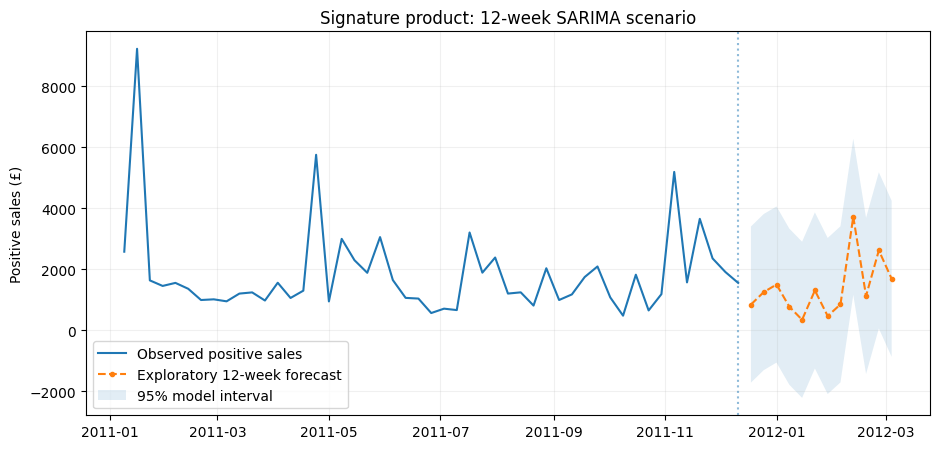

In [9]:
sarima_full = sm.tsa.statespace.SARIMAX(
    weekly_product, order=(0, 0, 0), seasonal_order=(1, 0, 0, seasonal_lag),
    enforce_stationarity=False, enforce_invertibility=False
).fit(disp=False)
future = sarima_full.get_forecast(steps=12)
future_mean = future.predicted_mean
future_ci = future.conf_int()
fig, ax = plt.subplots(figsize=(9.5, 4.6))
ax.plot(weekly_product.index, weekly_product.values, label="Observed positive sales")
ax.plot(future_mean.index, future_mean.values, label="Exploratory 12-week forecast",
        linestyle="--", marker=".")
ax.fill_between(future_ci.index, future_ci.iloc[:, 0].values,
                future_ci.iloc[:, 1].values, alpha=0.13, label="95% model interval")
ax.axvline(weekly_product.index[-1], linestyle=":", alpha=0.5)
ax.set(title="Signature product: 12-week SARIMA scenario", ylabel="Positive sales (£)")
ax.grid(alpha=0.18); ax.legend(); fig.tight_layout()
fig.savefig(FIG_DIR / "weekly_product_forecast.png", bbox_inches="tight")
plt.show()

## 8. Export and conclusions
RFM supports customer prioritisation but does not itself prove that a
marketing intervention will work. Validate against later transactions, and
reconcile cancellations for true net spending. Separate descriptive customer
segmentation from invoice-level quantity prediction and product forecasting.

In [10]:
metrics_export = {
    "data_quality": quality,
    "quarterly_product_sales_gbp": {str(k): float(v) for k,v in quarterly_product.items()},
    "rfm_segments": rfm_summary.reset_index().round(6).to_dict(orient="records"),
    "kmeans_clusters": cluster_summary.reset_index().round(6).to_dict(orient="records"),
    "statistical_tests": stat_results,
    "random_forest": rf_metrics.to_dict(orient="records"),
    "forecast_holdout": forecast_metrics
}
(OUTPUT_DIR / "audit_metrics.json").write_text(json.dumps(metrics_export, indent=2), encoding="utf-8")
print("\nAll results saved to figures/ and outputs/.")


All results saved to figures/ and outputs/.
